POTATO LEAF DISEASE DETECTION USING NEURAL NETS

In [ ]:
#pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [30]:
# importing neccessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import os
import cv2

In [31]:
#function to load images from folder

def load_img_from_folder(base_folder, img_size=(128,128)):
    data =[]
    for label in os.listdir(base_folder):   #early_blight / late_blight / healthy
        label_folder = os.path.join(base_folder,label)
        if not os.path.isdir(label_folder):
            continue
        for filename in os.listdir(label_folder):
            file_path = os.path.join(label_folder,filename)
            img = cv2.imread(file_path)
            if img is not None:
                img = cv2.resize(img,img_size)  #resize for consistency
                data.append((img,label))
    return data

In [32]:
#paths to all dataset - train / test / validation
test_path = "/Users/partha/AI_ML_Projects/Leaf-Disease-Detection-Neural-Nets/dataset/PLD_3_Classes_256/Testing"
train_path = "/Users/partha/AI_ML_Projects/Leaf-Disease-Detection-Neural-Nets/dataset/PLD_3_Classes_256/Training"
val_path = "/Users/partha/AI_ML_Projects/Leaf-Disease-Detection-Neural-Nets/dataset/PLD_3_Classes_256/Validation"

#load data using function above:
test_data = load_img_from_folder(test_path)
train_data = load_img_from_folder(train_path)
val_data = load_img_from_folder(val_path)

In [33]:
#lets combine the dataset
all_data = test_data + train_data + val_data

#create a dataframe
df = pd.DataFrame(all_data, columns=["image","label"])


In [34]:
print('Total Samples: ', len(df) ) ## 4072

Total Samples:  4072


In [35]:
row = df.iloc[0]
img = row["image"]

#Shape of image:
print("Shape of image: ", img.shape)    #Shape of image:  (128, 128, 3)
print("Size of image: ", img.size)      #Size of image:  49152

df["image"] = df["image"].apply(lambda img: cv2.resize(img,(224,224)))
print("New Shape: ", df.iloc[0]["image"].shape)     #New Shape:  (224, 224, 3)

Shape of image:  (128, 128, 3)
Size of image:  49152
New Shape:  (224, 224, 3)


In [36]:
#Train-Test Split
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print(train_df.shape)   #(3257, 2)
print(test_df.shape)    #(815, 2)

train_images = train_df["image"]
train_labels = train_df["label"]
test_images = test_df["image"]
test_labels = test_df["label"]

train_images = np.stack(train_images)
test_images = np.stack(test_images)

(3257, 2)
(815, 2)


In [40]:
train_images.shape

(3257, 224, 224, 3)

In [ ]:
#reshaping the train and test images:
train_images = train_images.reshape(train_images.shape[0],224,224,3) #3257,..
test_images = test_images.reshape(test_images.shape[0],224,224,3)

train_images = train_images/255
test_images = test_images/255

train_images = train_images.astype("float32")
test_images = test_images.astype("float32")

In [23]:
#pip install "numpy==1.23.5" "opencv-python<4.10"

In [41]:
#label encoder to labels:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
train_labels = le.fit_transform(train_labels)
test_labels = le.transform(test_labels)

#categorical labels:
import tensorflow
from tensorflow.keras.utils import to_categorical
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

[1. 0. 0.]
Sample:10 Label:[1. 0. 0.]


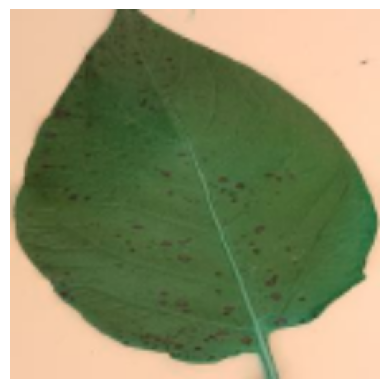

In [42]:
#Display the image:
def display_img(num):
    print(train_labels[num])
    image = train_images[num]
    print(f"Sample:{num} Label:{train_labels[num]}")
    plt.imshow(image)
    plt.axis('off')
    plt.show()

display_img(10)

Simple CNN build using Keras - Sequential Neural Net - Convolutional 2D NN

In [48]:
#lets first try to build a simple CNN for this:

#import neccesary modules:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Conv2D, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.activations import relu,softmax
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras import regularizers


In [51]:
#Define Input
input_shape = (224,224,3)

#add layers:
x = Sequential()
x.add(Conv2D(32, kernel_size=(3,3),activation='relu',input_shape = input_shape))
x.add(Conv2D(32, kernel_size=(3,3),activation='relu'))
x.add(GlobalAveragePooling2D())
x.add(Dense(128,activation='relu',kernel_regularizer=regularizers.l1_l2(1e-5)))
# x.add(Dropout(0.2))
# x.add(BatchNormalization())
x.add(Dense(64,activation='relu'))
x.add(Dropout(0.3))
x.add(BatchNormalization())
# x.add(Dense(32,activation='relu'))
# x.add(Dropout(0.2))
x.add(Dense(3,activation='softmax'))

In [52]:
x.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_13 (Conv2D)          (None, 222, 222, 32)      896       
                                                                 
 conv2d_14 (Conv2D)          (None, 220, 220, 32)      9248      
                                                                 
 global_average_pooling2d_6   (None, 32)               0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_21 (Dense)            (None, 128)               4224      
                                                                 
 dense_22 (Dense)            (None, 64)                8256      
                                                                 
 dropout_14 (Dropout)        (None, 64)                0         
                                                      

In [53]:
#model compilation
x.compile(loss='categorical_crossentropy',
          optimizer = Adam(learning_rate=0.001),
          metrics = ['accuracy'])

#early stopping defining:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7,verbose=1)

#model fitting:
x.fit(train_images,
          train_labels,
          validation_split = 0.2,
          epochs = 20,
          callbacks = [early_stop])

Epoch 1/20
82/82 [==============================] - 20s 222ms/step - loss: 1.5172 - accuracy: 0.4077 - val_loss: 1.3182 - val_accuracy: 0.4755
Epoch 2/20
82/82 [==============================] - 26s 319ms/step - loss: 1.2879 - accuracy: 0.4203 - val_loss: 1.2204 - val_accuracy: 0.4279
Epoch 3/20
82/82 [==============================] - 98s 1s/step - loss: 1.2361 - accuracy: 0.4123 - val_loss: 1.2915 - val_accuracy: 0.3436
Epoch 4/20
82/82 [==============================] - 111s 1s/step - loss: 1.1924 - accuracy: 0.4484 - val_loss: 1.2027 - val_accuracy: 0.4387
Epoch 5/20
82/82 [==============================] - 85s 1s/step - loss: 1.1730 - accuracy: 0.4672 - val_loss: 1.2285 - val_accuracy: 0.2868
Epoch 6/20
82/82 [==============================] - 75s 912ms/step - loss: 1.1174 - accuracy: 0.5225 - val_loss: 1.1602 - val_accuracy: 0.4509
Epoch 7/20
82/82 [==============================] - 67s 811ms/step - loss: 1.0899 - accuracy: 0.5497 - val_loss: 1.2024 - val_accuracy: 0.3113
Epoch 8

In [54]:
#lets evaluate the model:
x.evaluate(test_images,test_labels)

26/26 [==============================] - 2s 62ms/step - loss: 0.5997 - accuracy: 0.7681


[0.5997118353843689, 0.7680981755256653]

26/26 [==============================] - 1s 46ms/step


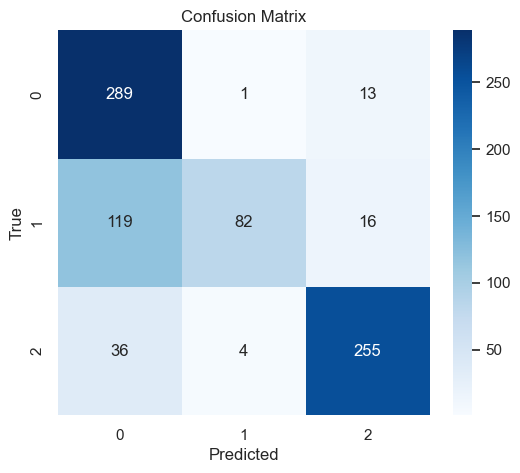

Accuracy Score -->  0.7680981595092025
Classification report:
               precision    recall  f1-score   support

           0       0.65      0.95      0.77       303
           1       0.94      0.38      0.54       217
           2       0.90      0.86      0.88       295

    accuracy                           0.77       815
   macro avg       0.83      0.73      0.73       815
weighted avg       0.82      0.77      0.75       815



In [56]:
#lets print the confusion matrix and the test accuracy
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = x.predict(test_images)
y_pred_classes = np.argmax(y_pred,axis=1)
y_true = np.argmax(test_labels,axis=1)

cm = confusion_matrix(y_true,y_pred_classes)
acc = accuracy_score(y_true,y_pred_classes)

#Printing the confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

#Printing the accuracy
print("Accuracy Score --> ", acc)

#Printing the classification report:
print("Classification report:\n", classification_report(y_true,y_pred_classes))
